# BÁO CÁO PHÂN TÍCH KHÁM PHÁ DỮ LIỆU (EDA)
## Đề tài: Khảo sát bài toán & Phân tích bộ dữ liệu Ames Housing
---
### Mục tiêu báo cáo:
1. **[1] Đọc paper & Khảo sát bài toán:**
2. **[2] Phân tích khám phá dữ liệu (EDA):**
   + Xác định tính chất
   + Phân tích đơn biến
   + Phân tích đa biến
   + Xác định giá trị thiếu, và mẫu bất thường
   + Xác định ngoại lệ

---
## PHẦN 1: Xác định tính chất
### 1.1. Bối cảnh từ Paper Dean De Cock (2011)
* **Lý do thay thế Boston Housing:** Bộ dữ liệu Boston Housing (1978) đã quá cũ kỹ (từ những năm 1970), quy mô nhỏ (chỉ 506 mẫu và 14 biến), giá nhà không còn thực tế đối với sinh viên hiện đại.
* **Nguồn gốc dữ liệu Ames:** Dữ liệu trích xuất từ **Văn phòng Thẩm định Giá Thành phố Ames (Ames City Assessor's Office)**, Iowa, ghi nhận các giao dịch nhà ở từ năm 2006 đến 2010.
* **Bài toán Kaggle:**
  * Thuộc lớp bài toán **Học có giám sát**, dạng **Hồi quy**.
  * **Biến mục tiêu (Target $Y$):** `SalePrice` (Giá bán của ngôi nhà bằng USD).
  * **Thước đo đánh giá (Evaluation Metric):** Đánh giá dựa trên sai số căn bậc hai trung bình logarit (**RMSLE**):
    $$\text{RMSLE} = \sqrt{\frac{1}{n} \sum_{i=1}^n \left( \log(\hat{y}_i) - \log(y_i) \right)^2}$$
    *Ý nghĩa:* Giúp đánh giá sai số theo tỷ lệ phần trăm chênh lệch, tạo sự công bằng giữa việc dự đoán các ngôi nhà giá rẻ và nhà giá cao.

In [34]:
# Import các thư viện cần thiết
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 120

# Đọc tập dữ liệu
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

print(f"Kích thước tập Train: {train.shape}")
print(f"Kích thước tập Test:  {test.shape}")

Kích thước tập Train: (1460, 81)
Kích thước tập Test:  (1459, 80)


In [35]:
# Xem qua 5 dòng đầu tiên của tập dữ liệu
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


### 1.2. Phân loại 79 đặc trưng theo Paper Dean De Cock
Theo tài liệu kỹ thuật của tác giả, 79 biến dự đoán được chia thành 4 nhóm cụ thể:
1. **20 Biến liên tục (Continuous):** Đo đạc kích thước diện tích (`LotFrontage`, `LotArea`, `TotalBsmtSF`, `GrLivArea`, `GarageArea`, `WoodDeckSF`,...).
2. **14 Biến rời rạc (Discrete):** Đếm số lượng phòng và năm xây dựng/cải tạo (`YearBuilt`, `YearRemodAdd`, `FullBath`, `HalfBath`, `BedroomAbvGr`, `TotRmsAbvGrd`, `GarageCars`,...).
3. **23 Biến định danh (Nominal):** Phân loại không có thứ bậc (`Neighborhood`, `MSZoning`, `BldgType`, `HouseStyle`, `Foundation`, `SaleType`, `SaleCondition`,...).
4. **23 Biến thứ bậc (Ordinal):** Đánh giá theo thang bậc chất lượng (`OverallQual`, `OverallCond`, `ExterQual`, `BsmtQual`, `KitchenQual`, `FireplaceQu`, `GarageQual`,...).

In [36]:
# Thống kê tổng số lượng cột số (Numerical) và cột định tính (Categorical)
num_features = train.select_dtypes(include=[np.number]).columns.drop(['Id', 'SalePrice'])
cat_features = train.select_dtypes(include=['object']).columns

print(f"Số lượng biến số (Numerical): {len(num_features)}")
print(f"Số lượng biến định tính (Categorical): {len(cat_features)}")

Số lượng biến số (Numerical): 36
Số lượng biến định tính (Categorical): 43


---
## PHẦN 2: PHÂN TÍCH ĐƠN BIẾN
### 2.1. Phân tích biến mục tiêu `SalePrice`
Ta kiểm tra các chỉ số thống kê mô tả cơ bản của `SalePrice` và kiểm tra độ lệch (Skewness) cùng độ nhọn (Kurtosis).

In [37]:
# Thống kê mô tả biến mục tiêu SalePrice
print("Thống kê mô tả SalePrice:")
print(train['SalePrice'].describe().apply(lambda x: f"{x:,.2f}"))
print(f"Độ lệch (Skewness): {train['SalePrice'].skew():.2f}")
print(f"Độ nhọn (Kurtosis): {train['SalePrice'].kurt():.2f}")

Thống kê mô tả SalePrice:
count      1,460.00
mean     180,921.20
std       79,442.50
min       34,900.00
25%      129,975.00
50%      163,000.00
75%      214,000.00
max      755,000.00
Name: SalePrice, dtype: str
Độ lệch (Skewness): 1.88
Độ nhọn (Kurtosis): 6.54


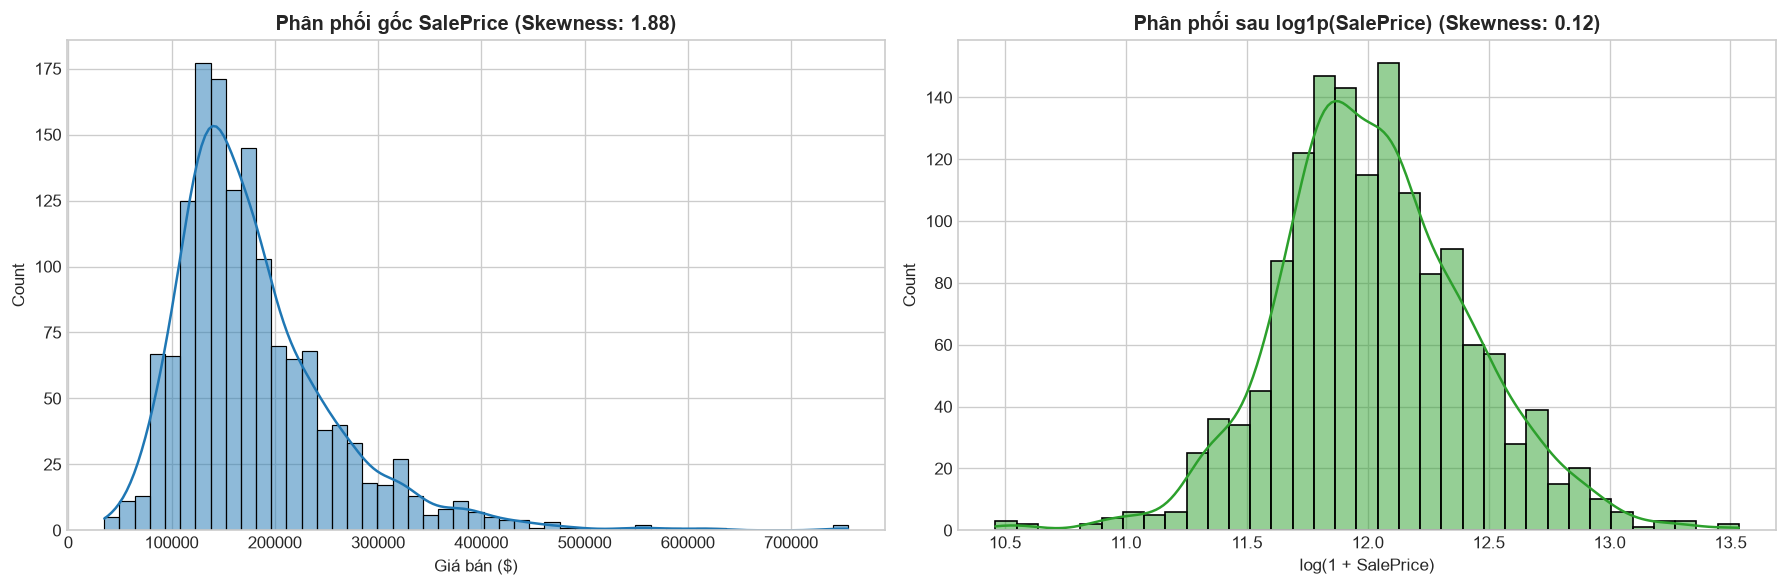

In [38]:
# Trực quan hóa phân phối SalePrice trước và sau khi Log-transform
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Phân phối gốc
sns.histplot(train['SalePrice'], kde=True, ax=axes[0], color='#1f77b4')
axes[0].set_title(f"Phân phối gốc SalePrice (Skewness: {train['SalePrice'].skew():.2f})", fontweight='bold')
axes[0].set_xlabel("Giá bán ($)")

# Phân phối sau Log-transform
log_saleprice = np.log1p(train['SalePrice'])
sns.histplot(log_saleprice, kde=True, ax=axes[1], color='#2ca02c')
axes[1].set_title(f"Phân phối sau log1p(SalePrice) (Skewness: {log_saleprice.skew():.2f})", fontweight='bold')
axes[1].set_xlabel("log(1 + SalePrice)")

plt.tight_layout()
plt.show()

**Nhận xét phân tích đơn biến `SalePrice`:**
* **Đặc trưng ban đầu:** Phân phối của `SalePrice` bị lệch phải rất rõ rệt (Right-skewed, Skewness = 1.88, Kurtosis = 6.54). Phần lớn giá nhà tập trung ở mức 130.000$ - 215.000$, nhưng có đuôi dài kéo sang bên phải do một số ít ngôi nhà cao cấp có giá lên đến 755.000$.
* **Hiệu quả Log-transform:** Sau khi lấy logarit $\log(1 + \text{SalePrice})$, độ lệch giảm ngoạn mục xuống còn 0.12, đưa phân phối về dạng hình chuông đối xứng (xấp xỉ phân phối chuẩn). Việc này hoàn toàn tương thích với tiêu chí RMSLE của Kaggle và giúp các mô hình hồi quy hoạt động hiệu quả hơn rất nhiều.

### 2.2. Phân phối của các biến đặc trưng định lượng quan trọng
Khảo sát phân phối của diện tích sinh hoạt trên mặt đất (`GrLivArea`), diện tích hầm (`TotalBsmtSF`) và năm xây dựng (`YearBuilt`).

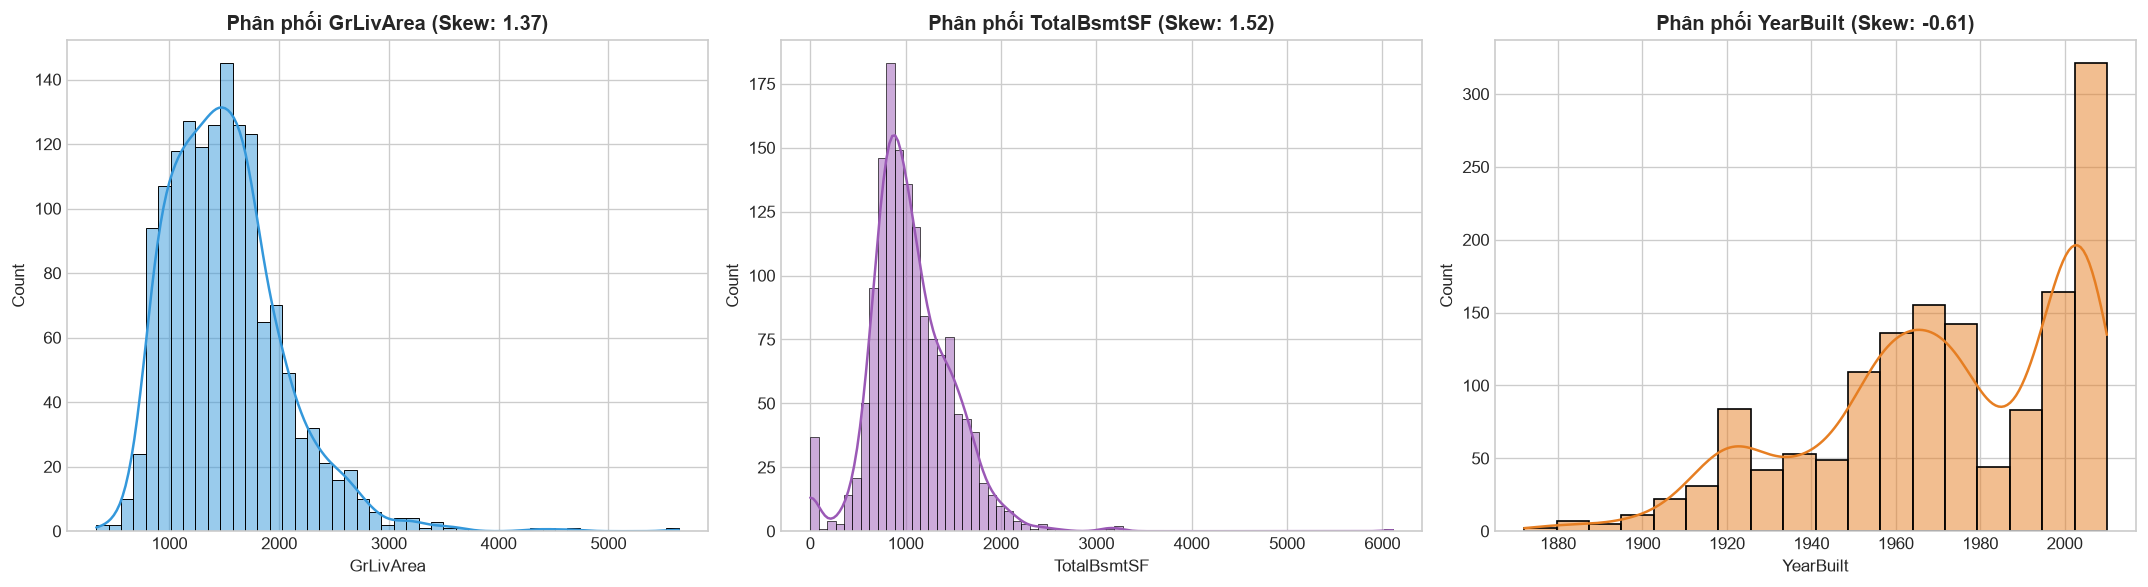

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(train['GrLivArea'], kde=True, ax=axes[0], color='#3498db')
axes[0].set_title(f"Phân phối GrLivArea (Skew: {train['GrLivArea'].skew():.2f})", fontweight='bold')

sns.histplot(train['TotalBsmtSF'], kde=True, ax=axes[1], color='#9b59b6')
axes[1].set_title(f"Phân phối TotalBsmtSF (Skew: {train['TotalBsmtSF'].skew():.2f})", fontweight='bold')

sns.histplot(train['YearBuilt'], kde=True, ax=axes[2], color='#e67e22')
axes[2].set_title(f"Phân phối YearBuilt (Skew: {train['YearBuilt'].skew():.2f})", fontweight='bold')

plt.tight_layout()
plt.show()

---
## PHẦN 3: PHÂN TÍCH ĐA BIẾN
### 3.1. Ma trận tương quan với `SalePrice`
Ta tìm các biến có hệ số tương quan Pearson ($r$) mạnh nhất đối với giá nhà.

Top 10 biến có tương quan mạnh nhất với SalePrice:
  - OverallQual    : r = 0.791
  - GrLivArea      : r = 0.709
  - GarageCars     : r = 0.640
  - GarageArea     : r = 0.623
  - TotalBsmtSF    : r = 0.614
  - 1stFlrSF       : r = 0.606
  - FullBath       : r = 0.561
  - TotRmsAbvGrd   : r = 0.534
  - YearBuilt      : r = 0.523
  - YearRemodAdd   : r = 0.507


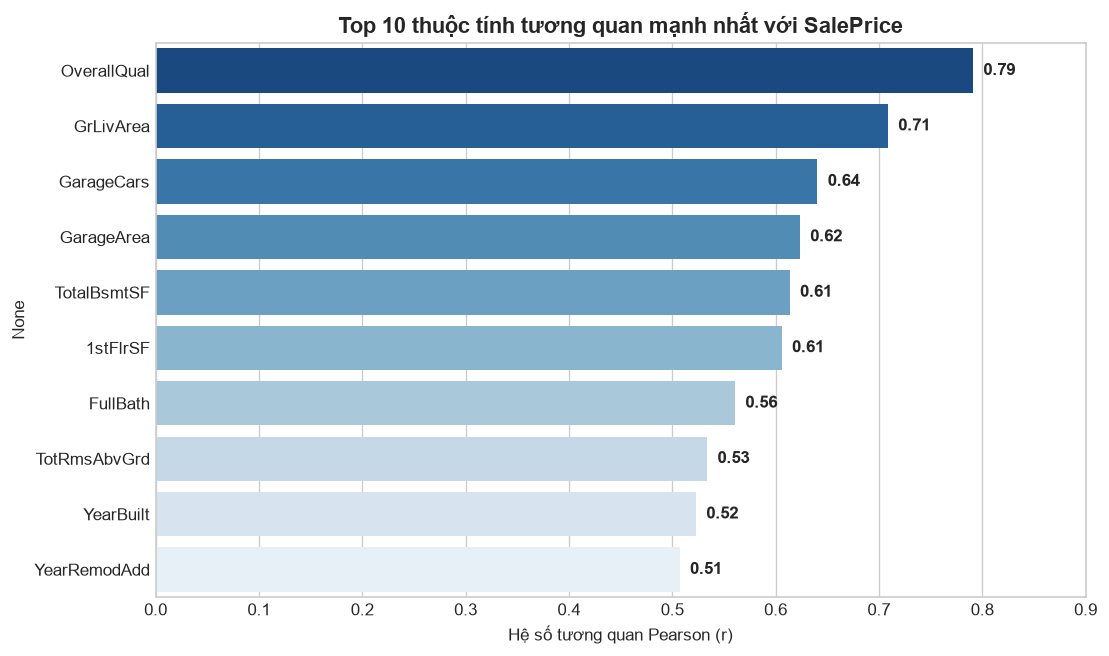

In [40]:
# Tính toán tương quan Pearson
corr_matrix = train[train.select_dtypes(include=[np.number]).columns].corr()
top_corr = corr_matrix['SalePrice'].sort_values(ascending=False)[1:11]

print("Top 10 biến có tương quan mạnh nhất với SalePrice:")
for feat, val in top_corr.items():
    print(f"  - {feat:15s}: r = {val:.3f}")

# Vẽ barplot Top 10 tương quan
plt.figure(figsize=(10, 6))
sns.barplot(x=top_corr.values, y=top_corr.index, palette='Blues_r')
plt.title("Top 10 thuộc tính tương quan mạnh nhất với SalePrice", fontsize=13, fontweight='bold')
plt.xlabel("Hệ số tương quan Pearson (r)")
for i, v in enumerate(top_corr.values):
    plt.text(v + 0.01, i, f"{v:.2f}", va='center', fontweight='bold')
plt.xlim(0, 0.9)
plt.show()

### 3.2. Kiểm tra hiện tượng Đa cộng tuyến (Multicollinearity)
Từ ma trận tương quan giữa các biến độc lập hàng đầu, ta nhận thấy một số cặp biến đo lường chung một đặc tính và có tương quan rất cao với nhau:

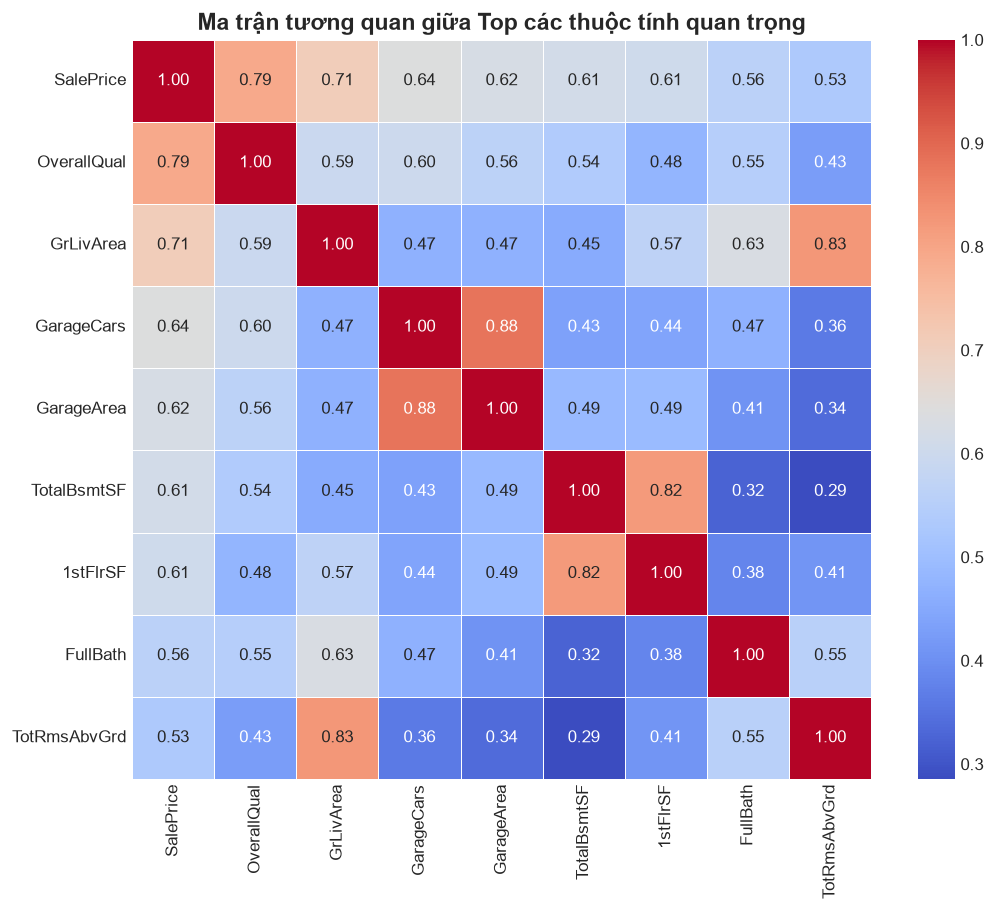

In [41]:
# Heatmap Top tương quan
top_features = ['SalePrice'] + list(top_corr.index[:8])
plt.figure(figsize=(10, 8))
sns.heatmap(train[top_features].corr(), annot=True, fmt='.2f', cmap='coolwarm', square=True, linewidths=0.5)
plt.title("Ma trận tương quan giữa Top các thuộc tính quan trọng", fontsize=14, fontweight='bold')
plt.show()

**Phát hiện hiện tượng đa cộng tuyến:**
* `GarageCars` và `GarageArea` có $r = 0.88$ (đều biểu thị độ lớn của nhà để xe: sức chứa số xe và diện tích).
* `TotalBsmtSF` và `1stFlrSF` có $r = 0.82$ (hầu hết nhà một tầng có diện tích tầng 1 bằng diện tích tầng hầm).
* `GrLivArea` và `TotRmsAbvGrd` có $r = 0.83$ (diện tích sàn nhà càng rộng thì số lượng phòng càng nhiều).
* `YearBuilt` và `GarageYrBlt` có $r = 0.83$ (thường gara được xây cùng năm với căn nhà).
* *Khuyến nghị:* Cần xem xét loại bỏ hoặc kết hợp các biến này khi sử dụng mô hình hồi quy tuyến tính cổ điển để tránh làm sai lệch ước lượng hệ số beta.

### 3.3. Tác động của Chất lượng tổng quan (`OverallQual`) và Vị trí (`Neighborhood`)

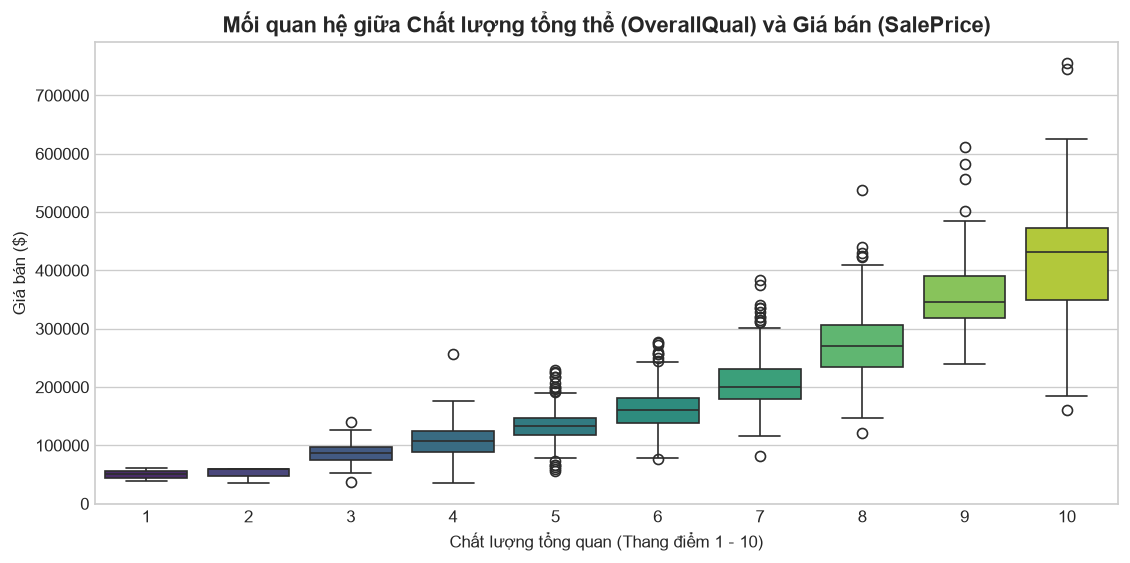

In [42]:
# Quan hệ giữa OverallQual và SalePrice
plt.figure(figsize=(11, 5))
sns.boxplot(x='OverallQual', y='SalePrice', data=train, palette='viridis')
plt.title("Mối quan hệ giữa Chất lượng tổng thể (OverallQual) và Giá bán (SalePrice)", fontsize=13, fontweight='bold')
plt.xlabel("Chất lượng tổng quan (Thang điểm 1 - 10)")
plt.ylabel("Giá bán ($)")
plt.show()

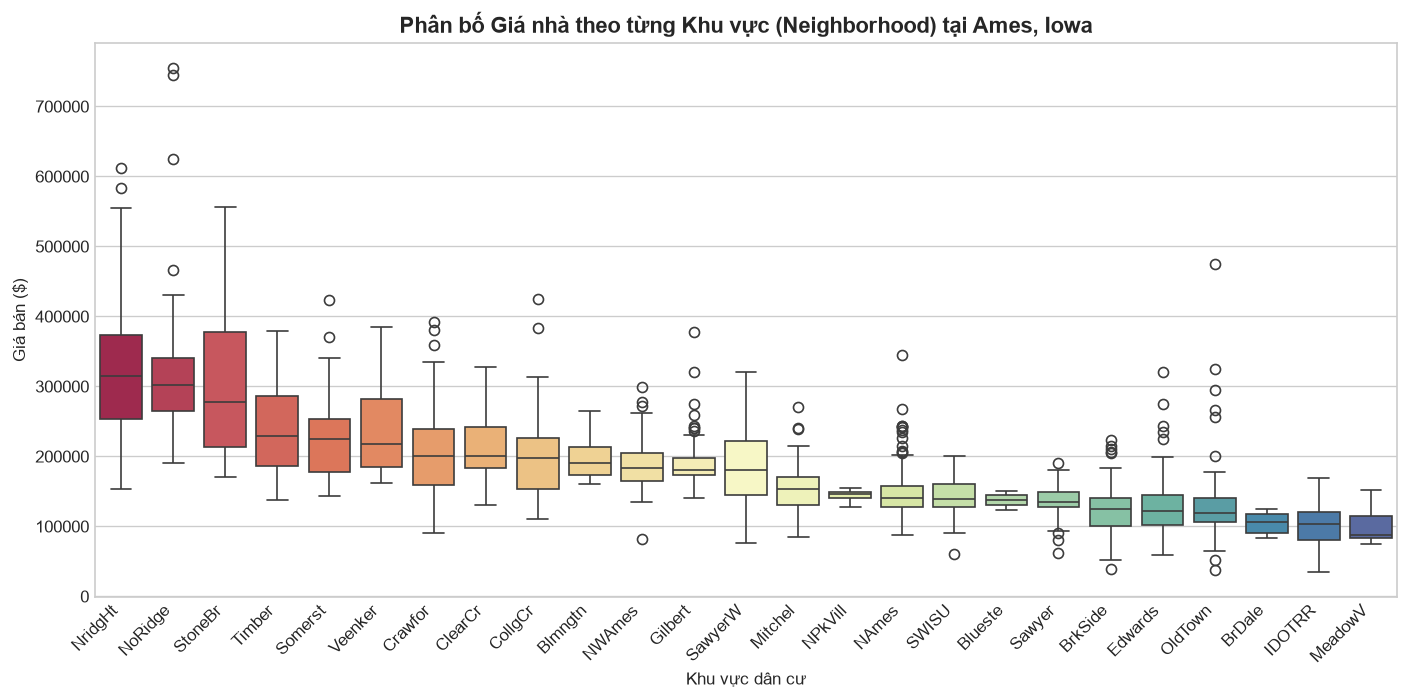

In [43]:
# Quan hệ giữa Khu vực (Neighborhood) và SalePrice
plt.figure(figsize=(14, 6))
order_neigh = train.groupby('Neighborhood')['SalePrice'].median().sort_values(ascending=False).index
sns.boxplot(x='Neighborhood', y='SalePrice', data=train, order=order_neigh, palette='Spectral')
plt.xticks(rotation=45, ha='right')
plt.title("Phân bố Giá nhà theo từng Khu vực (Neighborhood) tại Ames, Iowa", fontsize=13, fontweight='bold')
plt.xlabel("Khu vực dân cư")
plt.ylabel("Giá bán ($)")
plt.show()

---
## PHẦN 4: XÁC ĐỊNH GIÁ TRỊ THIẾU (MISSING DATA) & MẪU BẤT THƯỜNG
Ta kiểm tra toàn bộ các cột có chứa giá trị `NaN` và phân loại bản chất.

In [44]:
# Tính toán số lượng và tỷ lệ dữ liệu thiếu
missing = train.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_df = pd.DataFrame({
    'Số lượng khuyết': missing,
    'Tỷ lệ khuyết (%)': (missing / len(train)) * 100
})

missing_df.head(20)

,Số lượng khuyết,Tỷ lệ khuyết (%)
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


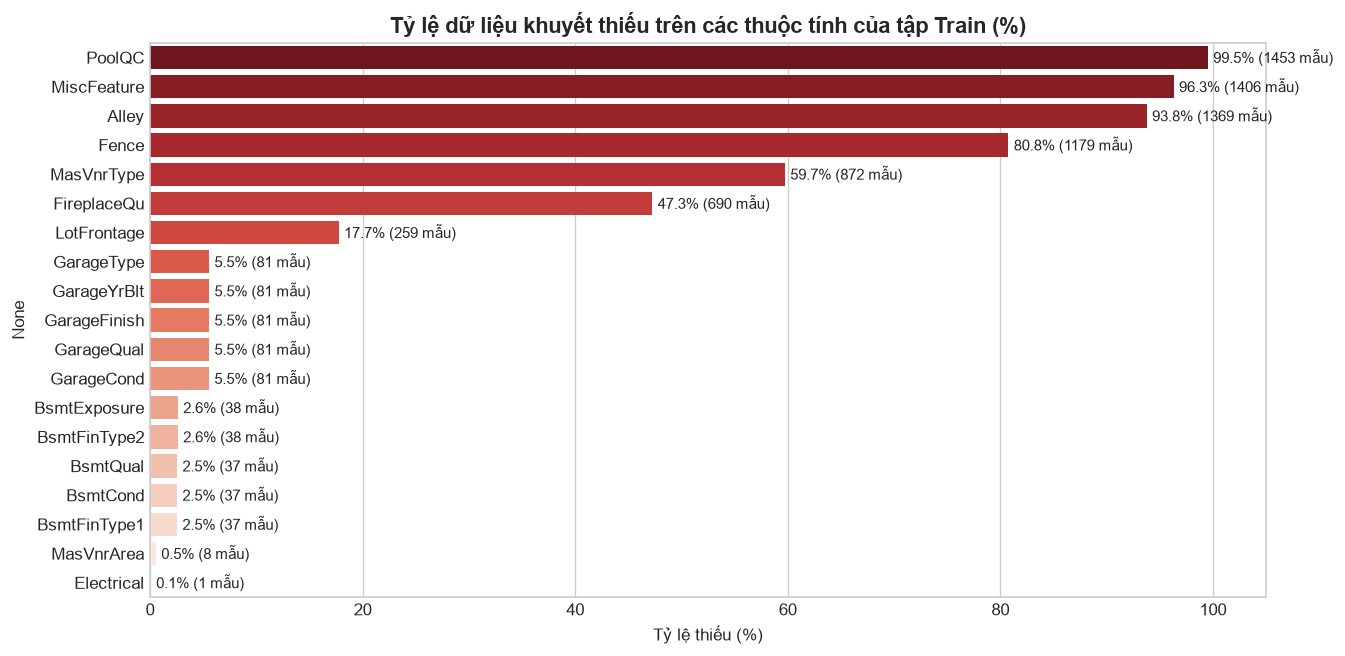

In [45]:
# Trực quan hóa tỷ lệ missing values
plt.figure(figsize=(12, 6))
sns.barplot(x=missing_df['Tỷ lệ khuyết (%)'], y=missing_df.index, palette='Reds_r')
plt.title("Tỷ lệ dữ liệu khuyết thiếu trên các thuộc tính của tập Train (%)", fontsize=13, fontweight='bold')
plt.xlabel("Tỷ lệ thiếu (%)")
for i, v in enumerate(missing_df['Tỷ lệ khuyết (%)']):
    plt.text(v + 0.5, i, f"{v:.1f}% ({missing_df['Số lượng khuyết'].iloc[i]} mẫu)", va='center', fontsize=9)
plt.xlim(0, 105)
plt.show()

**Phân tích bản chất dữ liệu khuyết:**
1. **Thiếu có cấu trúc (Structural Missing):**
   * Theo tài liệu `data_description.txt`, giá trị `NA` của các cột `PoolQC`, `MiscFeature`, `Alley`, `Fence`, `FireplaceQu` và các biến tiền tố `Garage*`, `Bsmt*` **không phải là dữ liệu bị mất**, mà biểu thị căn nhà **"không có tiện ích đó"** (Ví dụ: `PoolQC = NA` nghĩa là *No Pool*, `GarageType = NA` nghĩa là *No Garage*).
   * $\rightarrow$ *Giải pháp:* Điền chuỗi `'None'` cho các biến phân loại và điền số `0` cho các biến diện tích/số lượng tương ứng.
2. **Thiếu ngẫu nhiên (Random Missing):**
   * `LotFrontage` (17.7% thiếu): Chiều dài mặt tiền của lô đất. Nhà cùng một khu phố (`Neighborhood`) thường có quy hoạch mặt tiền tương đồng, do đó giải pháp tối ưu là **điền theo trung vị (Median) của từng khu phố**.
   * `MasVnrType` & `MasVnrArea` (0.5% thiếu): Điền `'None'` và `0`.
   * `Electrical` (1 mẫu thiếu): Điền theo Mode (`'SBrkr'`).

---
## PHẦN 5: PHÁT HIỆN MẪU DỊ THƯỜNG & NGOẠI LỆ (OUTLIERS)
### 5.1. Khuyến nghị trực tiếp từ Paper của Dean De Cock (2011)
Trong bài báo gốc (trang 4, mục *Potential Pitfalls (Outliers)*), tác giả Dean De Cock đã ghi rõ:
> *"There are five observations that an instructor may wish to remove from the data set before giving it to students (a plot of SALE PRICE versus GR LIV AREA will quickly indicate these points). Three of them are true outliers (Partial Sales that likely don’t represent actual market values) and two of them are simply unusual sales... I would recommend removing any houses with more than 4000 square feet from the data set before assigning it to students."*

Ta tiến hành trực quan hóa biểu đồ `GrLivArea` vs `SalePrice` để xác thực cảnh báo này trên tập Train của Kaggle:

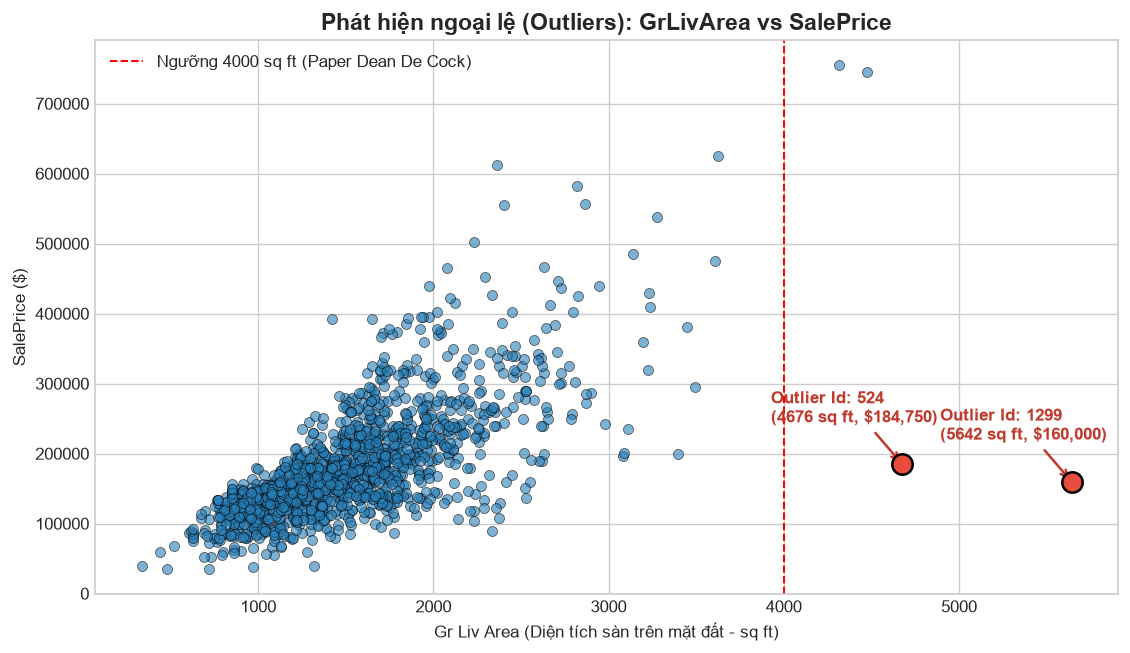

Thông tin chi tiết của các mẫu ngoại lai cực đoan trong tập Train:


,Id,GrLivArea,OverallQual,SalePrice,SaleType,SaleCondition
523,524,4676,10,184750,New,Partial
1298,1299,5642,10,160000,New,Partial


In [46]:
# Vẽ biểu đồ phân tán GrLivArea vs SalePrice và phát hiện Outliers
plt.figure(figsize=(11, 6))
plt.scatter(train['GrLivArea'], train['SalePrice'], alpha=0.6, color='#2980b9', edgecolors='k', linewidth=0.5)

# Tìm các điểm ngoại lai cực đoan (GrLivArea > 4000 và SalePrice < 200,000)
extreme_outliers = train[(train['GrLivArea'] > 4000) & (train['SalePrice'] < 200000)]
for _, row in extreme_outliers.iterrows():
    plt.scatter(row['GrLivArea'], row['SalePrice'], color='#e74c3c', s=150, edgecolors='black', linewidth=1.5, zorder=5)
    plt.annotate(f"Outlier Id: {row['Id']}\n({row['GrLivArea']} sq ft, ${row['SalePrice']:,})", 
                 xy=(row['GrLivArea'], row['SalePrice']),
                 xytext=(row['GrLivArea'] - 750, row['SalePrice'] + 60000),
                 arrowprops=dict(arrowstyle="->", color='#c0392b', lw=1.5),
                 fontsize=10, fontweight='bold', color='#c0392b')

plt.axvline(x=4000, color='red', linestyle='--', linewidth=1.2, label='Ngưỡng 4000 sq ft (Paper Dean De Cock)')
plt.title("Phát hiện ngoại lệ (Outliers): GrLivArea vs SalePrice", fontsize=14, fontweight='bold')
plt.xlabel("Gr Liv Area (Diện tích sàn trên mặt đất - sq ft)")
plt.ylabel("SalePrice ($)")
plt.legend()
plt.show()

print("Thông tin chi tiết của các mẫu ngoại lai cực đoan trong tập Train:")
extreme_outliers[['Id', 'GrLivArea', 'OverallQual', 'SalePrice', 'SaleType', 'SaleCondition']]

**Nhận xét về điểm ngoại lai:**
* Hai mẫu có `Id = 524` và `Id = 1299` có diện tích sinh hoạt cực kỳ lớn (lần lượt là $4676\text{ sq ft}$ và $5642\text{ sq ft}$ - lớn nhất toàn bộ tập dữ liệu), chất lượng đạt mức tối đa (`OverallQual = 10`), nhưng giá bán lại cực rẻ ($184.750\$$ và $160.000\$$).
* Như tác giả giải thích, đây là các giao dịch thuộc diện *Partial Sales* (nhà chưa hoàn thiện hoặc giao dịch bán nội bộ gia đình), không phản ánh giá trị thị trường thực tế.
* Nếu giữ lại 2 mẫu này, chúng sẽ kéo lệch hoàn toàn đường hồi quy của các biến diện tích. Do đó, **bắt buộc phải loại bỏ 2 mẫu Id 524 và 1299** khỏi tập huấn luyện trước khi xây dựng mô hình.

In [47]:
!jupyter nbconvert --to html "Lab03_EDA_house_prices.ipynb"

[NbConvertApp] Converting notebook Lab03_EDA_house_prices.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 8 image(s).
[NbConvertApp] Writing 1344890 bytes to Lab03_EDA_house_prices.html
